# Gemini version of 07 — within-subject RDM, drawings only

Parallel to the drawing side of `07_rsm_toself_analysis`: for each child, average the
`draw_probability_{category}` columns from `draw_cossim_toself.csv` into a 6x6
representational similarity matrix (row = category drawn, column = comparison
category, value = softmax probability), split at the median age, and average across
children within each age group. Again, this is drawings only.

Output: `figures/gemini_rdm_toself_drawings.png`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

IN_CSV = "../data/preprocessed/gemini/draw_cossim_toself.csv"
OUT_PNG = "../figures/gemini_rdm_toself_drawings.png"

CATEGORIES = ["crab", "octopus", "seahorse", "shark", "turtle", "whale"]
PROB_COLS = [f"draw_probability_{c}" for c in CATEGORIES]

# Interference trials (flagged in the tidy data) are excluded, as in the CLIP analyses
def interference_keys(path, col):
    t = pd.read_csv(path)
    return set(zip(t.loc[t[col] == 1, "participant_id"], t.loc[t[col] == 1, "target_category"]))


DRAW_INTERFERENCE = interference_keys("../data/tidy/drawings.csv", "draw_interference")
UTT_INTERFERENCE = interference_keys("../data/tidy/utterances.csv", "utterance_interference")


def drop_interference(df, keys):
    return df[[k not in keys for k in zip(df["participant_id"], df["target_category"])]].copy()

In [2]:
df = drop_interference(pd.read_csv(IN_CSV), DRAW_INTERFERENCE)
df["target_category"] = df["target_category"].str.lower().str.strip()

# Children only. drawing_highres_clean.csv (and everything downstream of it) already
# excludes pilot participants, so ~is_adult is a clean is_child here (verified: every
# participant_id is AD* or BD25+, no stray pilot/site codes).
children = df[~df["is_adult"]].copy()

n_missing_age = children["age_months"].isna().sum()
if n_missing_age:
    dropped = children.loc[children["age_months"].isna(), "participant_id"].unique().tolist()
    print(f"dropping {n_missing_age} row(s) with missing age_months: {dropped}")
    children = children.dropna(subset=["age_months"])

print(f"{children['participant_id'].nunique()} children, {len(children)} drawing rows")

dropping 9 row(s) with missing age_months: ['BD085', 'BD097']
88 children, 481 drawing rows


In [3]:
age_df = children.drop_duplicates("participant_id")[["participant_id", "age_months"]]
median_age = age_df["age_months"].median()

younger_ids = age_df.loc[age_df["age_months"] <= median_age, "participant_id"].tolist()
older_ids = age_df.loc[age_df["age_months"] > median_age, "participant_id"].tolist()

print(f"median age: {median_age/12:.2f} years")
print(f"younger: n={len(younger_ids)}, older: n={len(older_ids)}")

median age: 6.54 years
younger: n=44, older: n=44


In [4]:
def make_probability_rdm(df, pid, categories, prob_cols):
    """6x6 matrix: row i = mean softmax probs when the child drew categories[i]."""
    sub = df[df["participant_id"] == pid]
    rdm = np.full((len(categories), len(categories)), np.nan)
    for i, cat in enumerate(categories):
        cat_rows = sub[sub["target_category"] == cat]
        if len(cat_rows) > 0:
            rdm[i, :] = cat_rows[prob_cols].mean(axis=0, skipna=True).to_numpy()
    return rdm


def average_rdms(rdm_list):
    arr = np.stack(rdm_list, axis=0)
    with np.errstate(invalid="ignore"):
        return np.nanmean(arr, axis=0)

In [5]:
younger_rdms = [make_probability_rdm(children, pid, CATEGORIES, PROB_COLS) for pid in younger_ids]
older_rdms = [make_probability_rdm(children, pid, CATEGORIES, PROB_COLS) for pid in older_ids]

younger_rdm = average_rdms(younger_rdms)
older_rdm = average_rdms(older_rdms)

print("younger RDM:\n", np.round(younger_rdm, 3))
print("\nolder RDM:\n", np.round(older_rdm, 3))

younger RDM:
 [[  nan 0.239 0.206 0.223 0.22  0.206]
 [0.268   nan 0.195 0.215 0.217 0.204]
 [0.225 0.189   nan 0.204 0.211 0.242]
 [0.243 0.209 0.203   nan 0.221 0.232]
 [0.232 0.204 0.201 0.214   nan 0.196]
 [0.222 0.196 0.233 0.235 0.207   nan]]

older RDM:
 [[  nan 0.247 0.172 0.191 0.215 0.191]
 [0.252   nan 0.187 0.184 0.205 0.196]
 [0.196 0.207   nan 0.216 0.177 0.228]
 [0.192 0.18  0.186   nan 0.189 0.272]
 [0.232 0.216 0.166 0.204   nan 0.221]
 [0.188 0.187 0.193 0.266 0.2     nan]]


/var/folders/jl/8kq2x9q920v8l1fgdccdm_5r0000gt/T/ipykernel_68284/1124083310.py:15: RuntimeWarning: Mean of empty slice
  return np.nanmean(arr, axis=0)


saved -> ../figures/gemini_rdm_toself_drawings.png


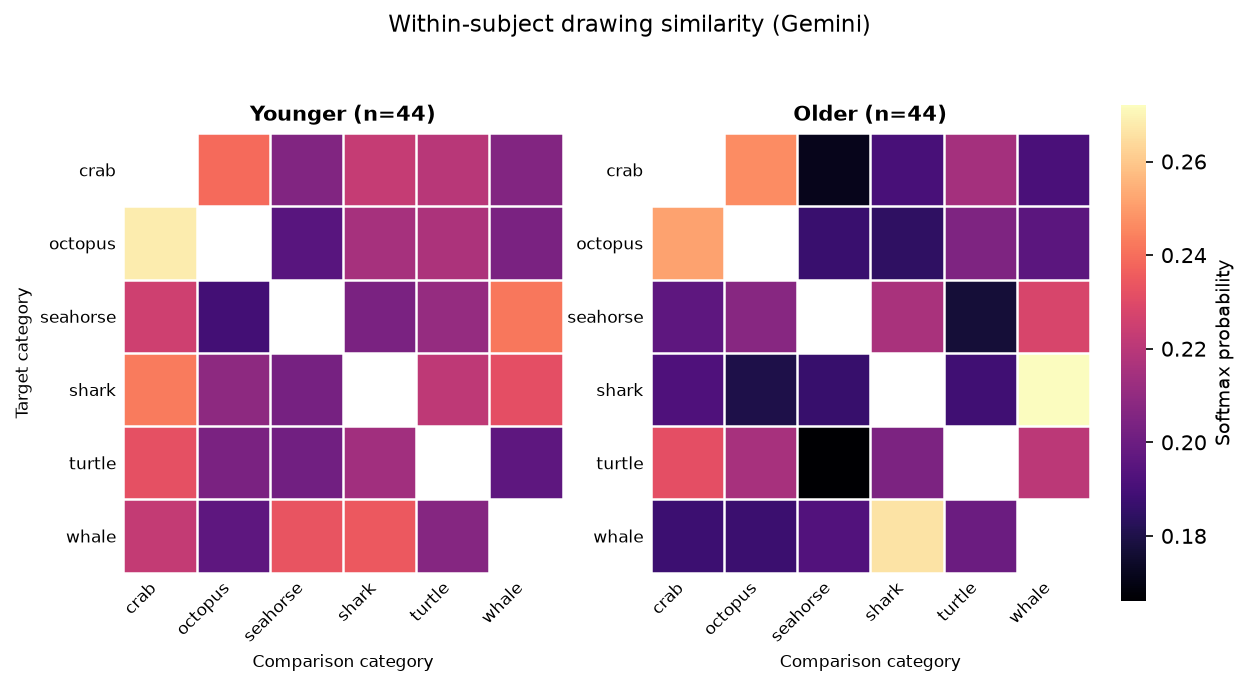

In [6]:
vmin = np.nanmin([younger_rdm, older_rdm])
vmax = np.nanmax([younger_rdm, older_rdm])

fig, axes = plt.subplots(1, 2, figsize=(9, 4.3), dpi=150)

for ax, mat, title, n in zip(
    axes, [younger_rdm, older_rdm], ["Younger", "Older"], [len(younger_ids), len(older_ids)]
):
    masked = np.ma.masked_invalid(mat)
    cmap = plt.get_cmap("magma").copy()
    cmap.set_bad("white")
    im = ax.imshow(masked, cmap=cmap, vmin=vmin, vmax=vmax, aspect="equal")

    ax.set_xticks(range(len(CATEGORIES)))
    ax.set_xticklabels(CATEGORIES, rotation=45, ha="right", fontsize=8)
    ax.set_yticks(range(len(CATEGORIES)))
    ax.set_yticklabels(CATEGORIES, fontsize=8)
    ax.set_title(f"{title} (n={n})", fontsize=10, fontweight="bold")
    ax.set_xlabel("Comparison category", fontsize=8)
    if ax is axes[0]:
        ax.set_ylabel("Target category", fontsize=8)

    # thin white gridlines between cells, no border box
    ax.set_xticks(np.arange(-0.5, len(CATEGORIES), 1), minor=True)
    ax.set_yticks(np.arange(-0.5, len(CATEGORIES), 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=1.2)
    ax.tick_params(which="minor", length=0)
    ax.tick_params(which="major", length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)

cbar = fig.colorbar(im, ax=axes, fraction=0.046, pad=0.03)
cbar.set_label("Softmax probability", size=9)
cbar.outline.set_visible(False)

fig.suptitle("Within-subject drawing similarity (Gemini)", fontsize=11, y=1.02)
fig.savefig(OUT_PNG, dpi=200, bbox_inches="tight")
print(f"saved -> {OUT_PNG}")
plt.show()

## Cross-modal RDM — drawings to text labels

Uses `draw_gemini_xmodal.csv` (`gemini_xmodal_cossim_{category}` = cosine(drawing,
"a drawing of a {category}")). Row = category drawn, column = text label, cell =
raw average cosine similarity — not softmax-scaled, unlike the within-modality RDM
above.

Three panels this time, not two: **younger children / older children** (same median
split as above) **and adults**.

Unlike the within-modality RDM, the diagonal here is a real, meaningful value — a
drawing's cosine similarity to its *own* category's text label — so it isn't
blanked. `make_probability_rdm`/`average_rdms` from above are reused unchanged;
only the input dataframe and column list differ.

Output: `figures/gemini_rdm_xmodal_drawings_to_text.png`.

In [7]:
XMODAL_CSV = "../data/embeddings/gemini/draw_gemini_xmodal.csv"
XMODAL_OUT_PNG = "../figures/gemini_rdm_xmodal_drawings_to_text.png"
XMODAL_COLS = [f"gemini_xmodal_cossim_{c}" for c in CATEGORIES]
XMODAL_Z_COLS = [f"{c}_z" for c in XMODAL_COLS]

xmodal_df = drop_interference(pd.read_csv(XMODAL_CSV), DRAW_INTERFERENCE)
xmodal_df["target_category"] = xmodal_df["target_category"].str.lower().str.strip()

# --- z-scoring so drawing and utterance figures share a scale and can be compared

# its own category from the others".
def zscore_cols(df, cols, z_cols):
    vals = df[cols].to_numpy(dtype=float)
    mu, sd = np.nanmean(vals), np.nanstd(vals)
    out = df.copy()
    out[z_cols] = (df[cols] - mu) / sd
    return out, mu, sd


xmodal_df, draw_mu, draw_sd = zscore_cols(xmodal_df, XMODAL_COLS, XMODAL_Z_COLS)
print(f"drawings: pooled cosine mean {draw_mu:.4f}, sd {draw_sd:.4f}")

# Shared colour limits for BOTH xmodal figures. Set once here because this cell
# runs first; the utterance cell reuses these names. Padded past the observed
# group-matrix range (-1.40 to 2.82 across both) so neither figure clips.
Z_VMIN, Z_VMAX = -1.5, 2.9

adult_ids = xmodal_df.loc[xmodal_df["is_adult"], "participant_id"].unique().tolist()

# Sanity check: younger_ids/older_ids came from draw_cossim_toself.csv above — confirm
# the same children are present here (both files derive from the same full-drawing set).
xmodal_children = set(xmodal_df.loc[~xmodal_df["is_adult"], "participant_id"])
missing = (set(younger_ids) | set(older_ids)) - xmodal_children
if missing:
    print(f"!! {len(missing)} child(ren) from the toself split missing in xmodal data: {missing}")
else:
    print("younger/older child IDs match between draw_cossim_toself.csv and draw_gemini_xmodal.csv")

print(f"adults: n={len(adult_ids)}")

drawings: pooled cosine mean 0.3860, sd 0.0367
younger/older child IDs match between draw_cossim_toself.csv and draw_gemini_xmodal.csv
adults: n=20


In [8]:
younger_xmodal_rdms = [make_probability_rdm(xmodal_df, pid, CATEGORIES, XMODAL_Z_COLS) for pid in younger_ids]
older_xmodal_rdms = [make_probability_rdm(xmodal_df, pid, CATEGORIES, XMODAL_Z_COLS) for pid in older_ids]
adult_xmodal_rdms = [make_probability_rdm(xmodal_df, pid, CATEGORIES, XMODAL_Z_COLS) for pid in adult_ids]

younger_xmodal_rdm = average_rdms(younger_xmodal_rdms)
older_xmodal_rdm = average_rdms(older_xmodal_rdms)
adult_xmodal_rdm = average_rdms(adult_xmodal_rdms)

xmodal_mats = [younger_xmodal_rdm, older_xmodal_rdm, adult_xmodal_rdm]
xmodal_titles = ["Younger", "Older", "Adults"]
xmodal_ns = [len(younger_ids), len(older_ids), len(adult_ids)]

# Averaging many participants pulls group cells well inside the per-row z range,
# so these matrices span roughly -1.4 to +2.4 rather than the raw z extremes.
for title, mat in zip(xmodal_titles, xmodal_mats):
    off = mat[~np.eye(len(CATEGORIES), dtype=bool)]
    diag = np.nanmean(np.diag(mat))
    print(f"\n{title} xmodal RDM (z) — diagonal {diag:+.3f}, off-diagonal "
          f"{np.nanmean(off):+.3f}, gap {diag - np.nanmean(off):+.3f}:\n",
          np.round(mat, 3))


Younger xmodal RDM (z) — diagonal +0.283, off-diagonal -0.278, gap +0.560:
 [[ 0.225  0.018 -0.388 -0.399  0.047 -0.104]
 [ 0.066  0.696 -0.314 -0.478 -0.064 -0.142]
 [-0.65  -0.495 -0.278 -0.738 -0.403 -0.436]
 [-0.245 -0.393 -0.237  0.138  0.035  0.371]
 [-0.026 -0.363 -0.514 -0.549  0.852 -0.093]
 [-0.474 -0.407 -0.441 -0.384 -0.127  0.063]]

Older xmodal RDM (z) — diagonal +1.672, off-diagonal -0.111, gap +1.783:
 [[ 1.41   0.231 -0.322 -0.421  0.06  -0.215]
 [ 0.383  1.848 -0.242 -0.526 -0.2   -0.243]
 [-0.584 -0.1    1.188 -0.301 -0.301  0.092]
 [-0.471 -0.767  0.02   1.738 -0.421  0.89 ]
 [ 0.429 -0.23  -0.189 -0.483  2.168  0.123]
 [-0.319 -0.326  0.284  0.876 -0.071  1.679]]

Adults xmodal RDM (z) — diagonal +2.093, off-diagonal -0.476, gap +2.569:
 [[ 1.974 -0.109 -0.667 -0.812 -0.04  -0.589]
 [ 0.243  2.37  -0.495 -0.785 -0.595 -0.58 ]
 [-0.704 -0.257  1.719 -0.372 -0.507 -0.047]
 [-1.061 -1.41  -0.571  2.086 -0.995  0.569]
 [-0.019 -0.766 -0.788 -1.088  2.252 -0.459]
 [-0.

saved -> ../figures/gemini_rdm_xmodal_drawings_to_text.png


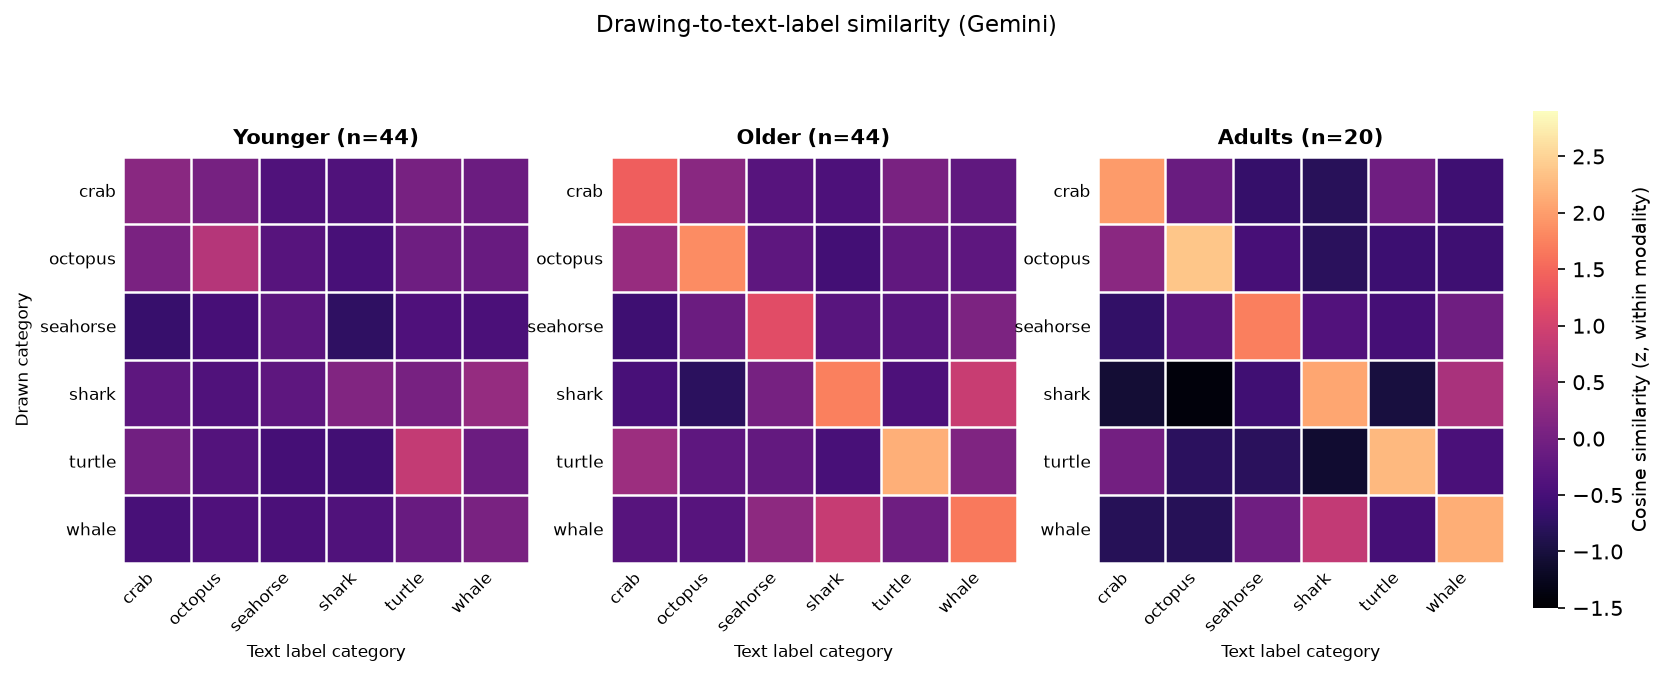

In [9]:
# xmodal_mats / titles / ns are built in the cell above. Colour limits are the
# shared Z_VMIN/Z_VMAX, not this figure's own min/max — using per-figure limits
# would re-introduce exactly the incomparability the z-scoring removed.
fig, axes = plt.subplots(1, 3, figsize=(12.5, 4.3), dpi=150)

for ax, mat, title, n in zip(axes, xmodal_mats, xmodal_titles, xmodal_ns):
    masked = np.ma.masked_invalid(mat)  # only masks genuinely missing rows, if any
    cmap = plt.get_cmap("magma").copy()
    cmap.set_bad("white")
    im = ax.imshow(masked, cmap=cmap, vmin=Z_VMIN, vmax=Z_VMAX, aspect="equal")

    ax.set_xticks(range(len(CATEGORIES)))
    ax.set_xticklabels(CATEGORIES, rotation=45, ha="right", fontsize=8)
    ax.set_yticks(range(len(CATEGORIES)))
    ax.set_yticklabels(CATEGORIES, fontsize=8)
    ax.set_title(f"{title} (n={n})", fontsize=10, fontweight="bold")
    ax.set_xlabel("Text label category", fontsize=8)
    if ax is axes[0]:
        ax.set_ylabel("Drawn category", fontsize=8)

    ax.set_xticks(np.arange(-0.5, len(CATEGORIES), 1), minor=True)
    ax.set_yticks(np.arange(-0.5, len(CATEGORIES), 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=1.2)
    ax.tick_params(which="minor", length=0)
    ax.tick_params(which="major", length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)

cbar = fig.colorbar(im, ax=axes, fraction=0.03, pad=0.02)
cbar.set_label("Cosine similarity (z, within modality)", size=9)
cbar.outline.set_visible(False)

fig.suptitle("Drawing-to-text-label similarity (Gemini)", fontsize=11, y=1.03)
fig.savefig(XMODAL_OUT_PNG, dpi=200, bbox_inches="tight")
print(f"saved -> {XMODAL_OUT_PNG}")
plt.show()

## Cross-modal RDM — utterances to text labels

The utterance parallel of the matrix above: same layout, same colormap, same
`make_probability_rdm`/`average_rdms` helpers. Row = the category the child was
describing, column = the text label, cell = mean cosine between the utterance
embedding and the label embedding. Built from `talk_gemini_xmodal.csv`
(`03g_talk_generate_gemini_embedding.ipynb`).


Output: `figures/gemini_rdm_xmodal_utterances_to_text.png`.

utterances: pooled cosine mean 0.6190, sd 0.0510 (drawings were 0.3860 / 0.0367)
talk median age: 6.58 years (drawings figure used 6.54)
younger: n=39 (2.58-6.58 yrs), older: n=40 (6.58-12.75 yrs)
  4 children share the median age, so the two groups touch at 6.58 yrs



Younger utterance xmodal RDM (z) — diagonal +0.617, off-diagonal -0.519, gap +1.135:
 [[ 0.118 -0.209 -0.788 -0.618 -0.996 -0.854]
 [-0.629  1.232 -0.84  -0.613 -0.943 -0.79 ]
 [-0.658 -0.197 -0.056 -0.463 -0.761 -0.4  ]
 [-0.854 -0.312 -0.421  0.821 -0.943  0.038]
 [-0.15  -0.031 -0.278 -0.233  0.952 -0.234]
 [-0.831 -0.23  -0.501  0.05  -0.867  0.634]]

Older utterance xmodal RDM (z) — diagonal +1.584, off-diagonal -0.144, gap +1.728:
 [[ 1.286  0.398 -0.143 -0.231 -0.344 -0.424]
 [-0.21   2.163 -0.363 -0.138 -0.575 -0.282]
 [-0.39   0.088  0.995 -0.185 -0.466 -0.101]
 [-0.511 -0.028 -0.13   1.512 -0.618  0.551]
 [ 0.007  0.04   0.026 -0.     1.835 -0.05 ]
 [-0.4    0.259 -0.142  0.576 -0.531  1.715]]

Adults utterance xmodal RDM (z) — diagonal +1.808, off-diagonal -0.034, gap +1.842:
 [[ 1.431e+00  3.700e-01 -1.370e-01 -3.460e-01 -1.650e-01 -5.430e-01]
 [-1.700e-02  2.822e+00 -8.600e-02  3.200e-02 -3.870e-01 -3.900e-02]
 [-4.890e-01  2.350e-01  9.530e-01 -1.160e-01 -5.850e-01 -2.00


saved -> ../figures/gemini_rdm_xmodal_utterances_to_text.png


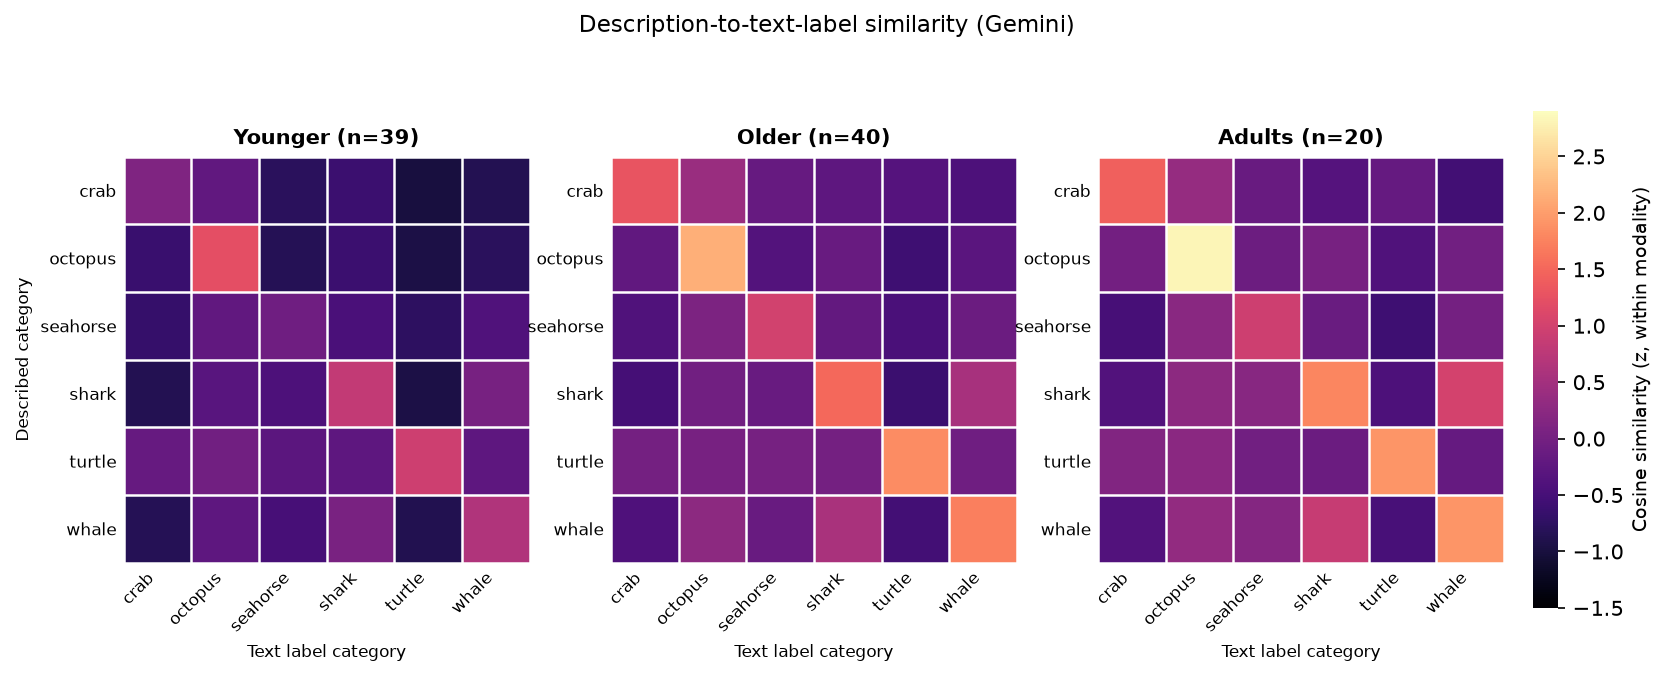

In [10]:
TALK_XMODAL_CSV = "../data/embeddings/gemini/talk_gemini_xmodal.csv"
TALK_XMODAL_OUT_PNG = "../figures/gemini_rdm_xmodal_utterances_to_text.png"

talk_xmodal_df = drop_interference(pd.read_csv(TALK_XMODAL_CSV), UTT_INTERFERENCE)
talk_xmodal_df["target_category"] = talk_xmodal_df["target_category"].str.lower().str.strip()

# Same within-modality standardisation as the drawings figure, using the helper
# and the shared Z_VMIN/Z_VMAX defined there, so the two colourbars match.
talk_xmodal_df, talk_mu, talk_sd = zscore_cols(
    talk_xmodal_df, XMODAL_COLS, XMODAL_Z_COLS)
print(f"utterances: pooled cosine mean {talk_mu:.4f}, sd {talk_sd:.4f} "
      f"(drawings were {draw_mu:.4f} / {draw_sd:.4f})")

talk_adult_ids = talk_xmodal_df.loc[talk_xmodal_df["is_adult"], "participant_id"].unique().tolist()

# The split is recomputed over the children actually IN this figure, as children did not always talk but tended to always draw.  

talk_children = talk_xmodal_df[~talk_xmodal_df["is_adult"]].copy()
draw_ages = children.drop_duplicates("participant_id").set_index("participant_id")["age_months"]
talk_children["age_months"] = talk_children["age_months"].fillna(
    talk_children["participant_id"].map(draw_ages))

no_age = talk_children.loc[talk_children["age_months"].isna(), "participant_id"].unique()
if len(no_age):
    print(f"dropping {len(no_age)} child(ren) with no age anywhere: {sorted(no_age)}")
    talk_children = talk_children.dropna(subset=["age_months"])

# Rank-halving rather than a <=/> median split, so n is equal in the two groups. If an odd number of children, the median child goes in the older group.
talk_age_df = (talk_children
               .drop_duplicates("participant_id")[["participant_id", "age_months"]]
               .sort_values(["age_months", "participant_id"])
               .reset_index(drop=True))

half = len(talk_age_df) // 2
talk_younger_ids = talk_age_df.loc[:half - 1, "participant_id"].tolist()
talk_older_ids = talk_age_df.loc[half:, "participant_id"].tolist()

talk_median_age = talk_age_df["age_months"].median()
n_tied = int((talk_age_df["age_months"] == talk_median_age).sum())
print(f"talk median age: {talk_median_age/12:.2f} years "
      f"(drawings figure used {median_age/12:.2f})")
print(f"younger: n={len(talk_younger_ids)} "
      f"({talk_age_df['age_months'][:half].min()/12:.2f}-"
      f"{talk_age_df['age_months'][:half].max()/12:.2f} yrs), "
      f"older: n={len(talk_older_ids)} "
      f"({talk_age_df['age_months'][half:].min()/12:.2f}-"
      f"{talk_age_df['age_months'][half:].max()/12:.2f} yrs)")
print(f"  {n_tied} children share the median age, so the two groups touch at "
      f"{talk_median_age/12:.2f} yrs")

talk_xmodal_mats = [
    average_rdms([make_probability_rdm(talk_xmodal_df, pid, CATEGORIES, XMODAL_Z_COLS)
                  for pid in ids])
    for ids in (talk_younger_ids, talk_older_ids, talk_adult_ids)
]
talk_xmodal_ns = [len(talk_younger_ids), len(talk_older_ids), len(talk_adult_ids)]

for title, mat in zip(xmodal_titles, talk_xmodal_mats):
    off = mat[~np.eye(len(CATEGORIES), dtype=bool)]
    diag = np.nanmean(np.diag(mat))
    print(f"\n{title} utterance xmodal RDM (z) — diagonal {diag:+.3f}, "
          f"off-diagonal {np.nanmean(off):+.3f}, gap {diag - np.nanmean(off):+.3f}:\n",
          np.round(mat, 3))


fig, axes = plt.subplots(1, 3, figsize=(12.5, 4.3), dpi=150)

for ax, mat, title, n in zip(axes, talk_xmodal_mats, xmodal_titles, talk_xmodal_ns):
    masked = np.ma.masked_invalid(mat)
    cmap = plt.get_cmap("magma").copy()
    cmap.set_bad("white")
    im = ax.imshow(masked, cmap=cmap, vmin=Z_VMIN, vmax=Z_VMAX, aspect="equal")

    ax.set_xticks(range(len(CATEGORIES)))
    ax.set_xticklabels(CATEGORIES, rotation=45, ha="right", fontsize=8)
    ax.set_yticks(range(len(CATEGORIES)))
    ax.set_yticklabels(CATEGORIES, fontsize=8)
    ax.set_title(f"{title} (n={n})", fontsize=10, fontweight="bold")
    ax.set_xlabel("Text label category", fontsize=8)
    if ax is axes[0]:
        ax.set_ylabel("Described category", fontsize=8)

    ax.set_xticks(np.arange(-0.5, len(CATEGORIES), 1), minor=True)
    ax.set_yticks(np.arange(-0.5, len(CATEGORIES), 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=1.2)
    ax.tick_params(which="minor", length=0)
    ax.tick_params(which="major", length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)

cbar = fig.colorbar(im, ax=axes, fraction=0.03, pad=0.02)
cbar.set_label("Cosine similarity (z, within modality)", size=9)
cbar.outline.set_visible(False)

fig.suptitle("Description-to-text-label similarity (Gemini)", fontsize=11, y=1.03)
fig.savefig(TALK_XMODAL_OUT_PNG, dpi=200, bbox_inches="tight")
print(f"\nsaved -> {TALK_XMODAL_OUT_PNG}")
plt.show()

## Within-child RDM — each child's drawings to their *own* descriptions

The two matrices above compare a participant's output against a generic category
label.How do children's own descriptions compare to their own drawings? 

The cosine similarity of a drawing and description is computed **per child
first**, then averaged across children within an age group to measure how an individual 
child's drawings and descriptions relate over development

Missing data is handled cell by cell via `np.nanmean`. A child with no whale
drawing contributes nothing to the whale *row*; a child with no whale description
contributes nothing to the whale *column*; the rest of their matrix still counts.
No child is dropped for partial data. 74 participants (including adults) have all six
diagonal cells, indicating they have a drawing and description for each category.

Output: `figures/gemini_rdm_drawing_to_own_description.png`.

drawing embeddings: 610  |  utterance embeddings: 538
participants with at least one cell: 98
  cells per participant (max 36): median 36, min 3
  participants with all 6 diagonal cells: 70/98

median child age: 6.62 years
younger: n=39, older: n=39, adults: n=20  [rank-halved for equal n]

pooled over 3131 participant-level cells: raw cosine mean 0.3759, sd 0.0310

Younger drawing-to-own-description RDM (z) — diagonal +0.147, off-diagonal -0.348, gap +0.495:
 [[ 0.126 -0.278 -0.194 -0.631 -0.266 -0.337]
 [-0.01   0.34  -0.163 -0.536 -0.4   -0.19 ]
 [-0.627 -0.865  0.005 -0.826 -0.761 -0.441]
 [-0.241 -0.487  0.019  0.197 -0.186  0.082]
 [-0.124 -0.378 -0.127 -0.465  0.305  0.159]
 [-0.514 -0.597 -0.134 -0.412 -0.513 -0.092]]

Older drawing-to-own-description RDM (z) — diagonal +1.107, off-diagonal -0.090, gap +1.197:
 [[ 0.958  0.083  0.144 -0.342 -0.038  0.086]
 [ 0.347  1.259  0.05  -0.409 -0.313  0.071]
 [-0.546 -0.622  0.688 -0.485 -0.64  -0.063]
 [-0.375 -0.497  0.116  1.064 -0.4


saved -> ../figures/gemini_rdm_drawing_to_own_description.png


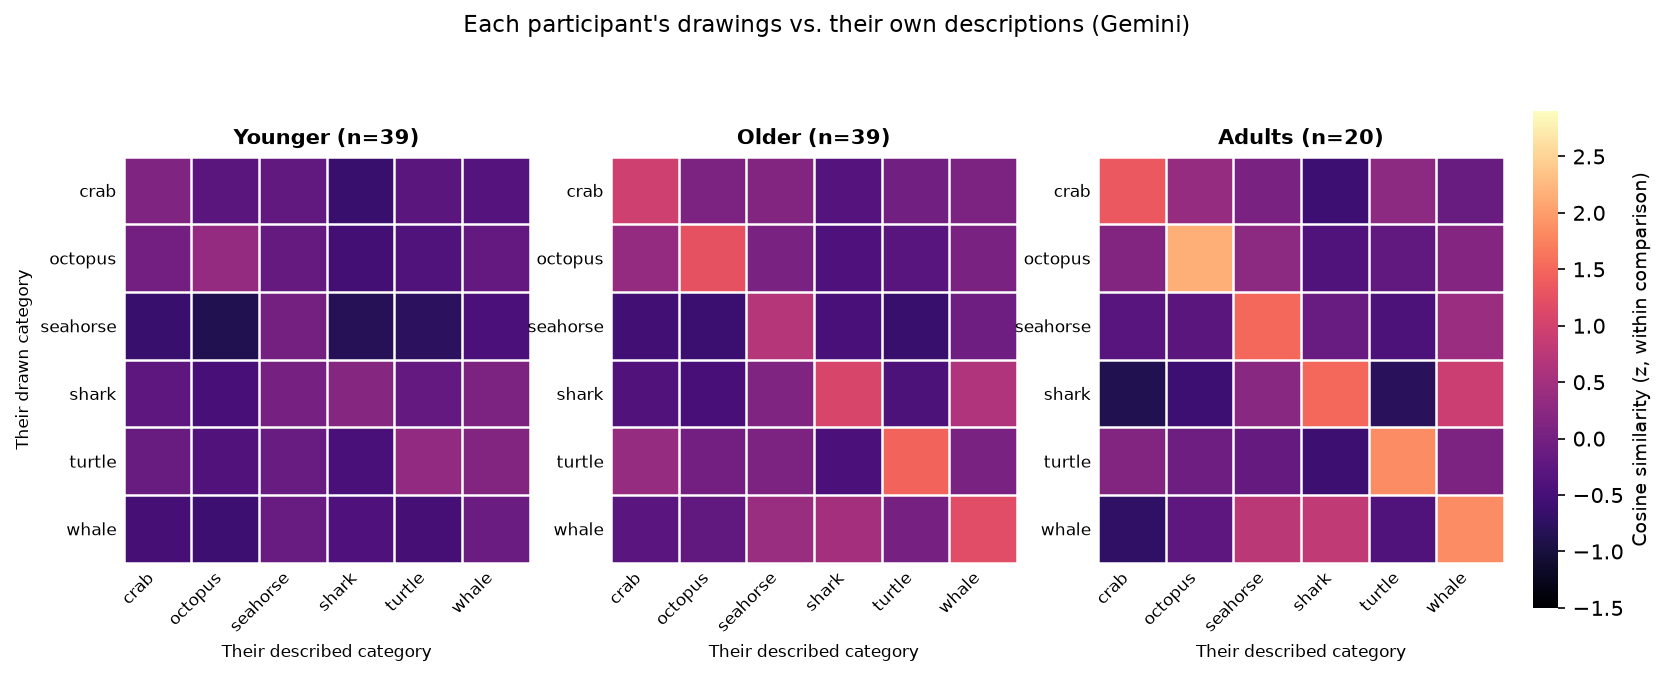

In [11]:
import ast

DRAW_EMB_CSV = "../data/embeddings/gemini/draw_gemini_embeddings_full.csv"
UTT_EMB_CSV = "../data/embeddings/gemini/utterance_gemini_embeddings.csv"
SELF_OUT_PNG = "../figures/gemini_rdm_drawing_to_own_description.png"

# Equal group sizes via rank-halving, as in the utterance figure.

EQUAL_GROUP_N = True


def parse_vec(v):
    """Embeddings are stored as list literals in the CSVs."""
    if pd.isna(v):
        return None
    a = np.asarray(ast.literal_eval(v), dtype=np.float32)
    return a if a.size else None


def cosine_vec(a, b):
    return float(np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b)))


draw_emb = drop_interference(pd.read_csv(DRAW_EMB_CSV), DRAW_INTERFERENCE)
draw_emb["cat"] = draw_emb["target_category"].str.lower().str.strip()
draw_emb["vec"] = draw_emb["embedding"].apply(parse_vec)

utt_emb = drop_interference(pd.read_csv(UTT_EMB_CSV), UTT_INTERFERENCE)
utt_emb["cat"] = utt_emb["target_category"].str.lower().str.strip()
utt_emb["vec"] = utt_emb["utterance_full_embedding"].apply(parse_vec)
utt_emb = utt_emb[utt_emb["vec"].notna()]

print(f"drawing embeddings: {draw_emb['vec'].notna().sum()}  |  "
      f"utterance embeddings: {len(utt_emb)}")

draw_lookup = {(r.participant_id, r.cat): r.vec
               for r in draw_emb.itertuples() if r.vec is not None}
utt_lookup = {(r.participant_id, r.cat): r.vec for r in utt_emb.itertuples()}

# One 6x6 per participant: cosine(their drawing of row, their description of col).
# NaN wherever either side is missing, so that cell simply drops out of the mean.
self_mats = {}
cell_counts = []
for pid in sorted(set(draw_emb["participant_id"]) | set(utt_emb["participant_id"])):
    m = np.full((len(CATEGORIES), len(CATEGORIES)), np.nan)
    for i, ci in enumerate(CATEGORIES):
        dv = draw_lookup.get((pid, ci))
        if dv is None:
            continue
        for j, cj in enumerate(CATEGORIES):
            uv = utt_lookup.get((pid, cj))
            if uv is None:
                continue
            m[i, j] = cosine_vec(dv, uv)
    n_cells = int(np.isfinite(m).sum())
    if n_cells:
        self_mats[pid] = m
        cell_counts.append({"participant_id": pid, "n_cells": n_cells,
                            "n_diag": int(np.isfinite(np.diag(m)).sum())})

cell_counts = pd.DataFrame(cell_counts)
print(f"participants with at least one cell: {len(self_mats)}")
print(f"  cells per participant (max 36): median "
      f"{cell_counts['n_cells'].median():.0f}, min {cell_counts['n_cells'].min()}")
print(f"  participants with all 6 diagonal cells: "
      f"{(cell_counts['n_diag'] == 6).sum()}/{len(cell_counts)}")

# Ages from whichever embedding file has them; a participant appears in both.
self_ages = (pd.concat([draw_emb[["participant_id", "age_months", "is_adult"]],
                        utt_emb[["participant_id", "age_months", "is_adult"]]])
             .dropna(subset=["age_months"])
             .drop_duplicates("participant_id")
             .set_index("participant_id"))

present = [p for p in self_mats if p in self_ages.index]
missing_age = sorted(set(self_mats) - set(present))
if missing_age:
    print(f"  dropping {len(missing_age)} participant(s) with no age: {missing_age}")

self_kids = self_ages.loc[present]
self_kids = self_kids[~self_kids["is_adult"]].sort_values("age_months")
self_adult_ids = self_ages.loc[present][self_ages.loc[present]["is_adult"]].index.tolist()

if EQUAL_GROUP_N:
    ranked = self_kids.reset_index()
    half = len(ranked) // 2
    self_younger_ids = ranked["participant_id"][:half].tolist()
    self_older_ids = ranked["participant_id"][half:].tolist()
else:
    med = self_kids["age_months"].median()
    self_younger_ids = self_kids[self_kids["age_months"] <= med].index.tolist()
    self_older_ids = self_kids[self_kids["age_months"] > med].index.tolist()

self_median_age = self_kids["age_months"].median()
print(f"\nmedian child age: {self_median_age/12:.2f} years")
print(f"younger: n={len(self_younger_ids)}, older: n={len(self_older_ids)}, "
      f"adults: n={len(self_adult_ids)}"
      f"{'  [rank-halved for equal n]' if EQUAL_GROUP_N else ''}")


# Standardise before averaging so that the drawing-to-own-description RDMs are on the same scale as the
_self_stack = np.stack(list(self_mats.values()), axis=0)
self_mu, self_sd = np.nanmean(_self_stack), np.nanstd(_self_stack)
print(f"\npooled over {int(np.isfinite(_self_stack).sum())} participant-level cells: "
      f"raw cosine mean {self_mu:.4f}, sd {self_sd:.4f}")
self_mats = {pid: (m - self_mu) / self_sd for pid, m in self_mats.items()}


def average_self_mats(pids):
    """Mean over participants, skipping NaN cells rather than whole participants."""
    with np.errstate(invalid="ignore"):
        return np.nanmean(np.stack([self_mats[p] for p in pids], axis=0), axis=0)


self_mats_grouped = [average_self_mats(ids) for ids in
                     (self_younger_ids, self_older_ids, self_adult_ids)]
self_ns = [len(self_younger_ids), len(self_older_ids), len(self_adult_ids)]

for title, mat in zip(xmodal_titles, self_mats_grouped):
    off = mat[~np.eye(len(CATEGORIES), dtype=bool)]
    diag = np.nanmean(np.diag(mat))
    print(f"\n{title} drawing-to-own-description RDM (z) — diagonal {diag:+.3f}, "
          f"off-diagonal {np.nanmean(off):+.3f}, gap {diag - np.nanmean(off):+.3f}:\n",
          np.round(mat, 3))

# Shared limits with both label-similarity figures for comparability 
print(f"\nthis figure spans z {np.nanmin(self_mats_grouped):+.3f} to "
      f"{np.nanmax(self_mats_grouped):+.3f} on a {Z_VMIN} to {Z_VMAX} scale")

fig, axes = plt.subplots(1, 3, figsize=(12.5, 4.3), dpi=150)

for ax, mat, title, n in zip(axes, self_mats_grouped, xmodal_titles, self_ns):
    masked = np.ma.masked_invalid(mat)
    cmap = plt.get_cmap("magma").copy()
    cmap.set_bad("white")
    im = ax.imshow(masked, cmap=cmap, vmin=Z_VMIN, vmax=Z_VMAX, aspect="equal")

    ax.set_xticks(range(len(CATEGORIES)))
    ax.set_xticklabels(CATEGORIES, rotation=45, ha="right", fontsize=8)
    ax.set_yticks(range(len(CATEGORIES)))
    ax.set_yticklabels(CATEGORIES, fontsize=8)
    ax.set_title(f"{title} (n={n})", fontsize=10, fontweight="bold")
    ax.set_xlabel("Their described category", fontsize=8)
    if ax is axes[0]:
        ax.set_ylabel("Their drawn category", fontsize=8)

    ax.set_xticks(np.arange(-0.5, len(CATEGORIES), 1), minor=True)
    ax.set_yticks(np.arange(-0.5, len(CATEGORIES), 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=1.2)
    ax.tick_params(which="minor", length=0)
    ax.tick_params(which="major", length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)

cbar = fig.colorbar(im, ax=axes, fraction=0.03, pad=0.02)
cbar.set_label("Cosine similarity (z, within comparison)", size=9)
cbar.outline.set_visible(False)

fig.suptitle("Each participant's drawings vs. their own descriptions (Gemini)",
             fontsize=11, y=1.03)
fig.savefig(SELF_OUT_PNG, dpi=200, bbox_inches="tight")
print(f"\nsaved -> {SELF_OUT_PNG}")
plt.show()

## Cross-modal correlation — drawings vs. utterances

How correlated are the relationships between categories for children's utterances and descriptions? Here, we do a Spearman correlation of the lower triangle of utterance and drawing RDMs for category pairs (e.g., whale-shark)

Median age split comes from the *union* of children with
either drawings or utterances. 

In [12]:
TALK_CSV = "../data/preprocessed/gemini/talk_cossim_toself.csv"
UTT_PROB_COLS = [f"utterance_probability_{c}" for c in CATEGORIES]

talk_df = drop_interference(pd.read_csv(TALK_CSV), UTT_INTERFERENCE)
talk_df["target_category"] = talk_df["target_category"].str.lower().str.strip()
talk_children = talk_df[~talk_df["is_adult"]].dropna(subset=["age_months"]).copy()

# Union of drawing-children and talk-children ages, matching the original notebook's age_df
combined_age_df = pd.concat([
    children.drop_duplicates("participant_id")[["participant_id", "age_months"]],
    talk_children.drop_duplicates("participant_id")[["participant_id", "age_months"]],
]).drop_duplicates("participant_id")

combined_median_age = combined_age_df["age_months"].median()
cm_younger_ids = combined_age_df.loc[combined_age_df["age_months"] <= combined_median_age, "participant_id"].tolist()
cm_older_ids = combined_age_df.loc[combined_age_df["age_months"] > combined_median_age, "participant_id"].tolist()

print(f"combined median age: {combined_median_age/12:.3f} years")
print(f"younger: n={len(cm_younger_ids)}, older: n={len(cm_older_ids)}")

combined median age: 6.500 years
younger: n=46, older: n=44


In [13]:
cm_draw_younger_rdm = average_rdms([make_probability_rdm(children, pid, CATEGORIES, PROB_COLS) for pid in cm_younger_ids])
cm_draw_older_rdm = average_rdms([make_probability_rdm(children, pid, CATEGORIES, PROB_COLS) for pid in cm_older_ids])

utt_younger_rdm = average_rdms([make_probability_rdm(talk_children, pid, CATEGORIES, UTT_PROB_COLS) for pid in cm_younger_ids])
utt_older_rdm = average_rdms([make_probability_rdm(talk_children, pid, CATEGORIES, UTT_PROB_COLS) for pid in cm_older_ids])

print("utterance younger RDM:\n", np.round(utt_younger_rdm, 3))
print("\nutterance older RDM:\n", np.round(utt_older_rdm, 3))

/var/folders/jl/8kq2x9q920v8l1fgdccdm_5r0000gt/T/ipykernel_68284/1124083310.py:15: RuntimeWarning: Mean of empty slice
  return np.nanmean(arr, axis=0)
/var/folders/jl/8kq2x9q920v8l1fgdccdm_5r0000gt/T/ipykernel_68284/1124083310.py:15: RuntimeWarning: Mean of empty slice
  return np.nanmean(arr, axis=0)
/var/folders/jl/8kq2x9q920v8l1fgdccdm_5r0000gt/T/ipykernel_68284/1124083310.py:15: RuntimeWarning: Mean of empty slice
  return np.nanmean(arr, axis=0)


utterance younger RDM:
 [[  nan 0.226 0.215 0.184 0.225 0.196]
 [0.244   nan 0.195 0.22  0.201 0.215]
 [0.232 0.194   nan 0.198 0.235 0.21 ]
 [0.204 0.218 0.202   nan 0.205 0.276]
 [0.231 0.19  0.226 0.186   nan 0.21 ]
 [0.209 0.21  0.2   0.263 0.216   nan]]

utterance older RDM:
 [[  nan 0.226 0.205 0.187 0.216 0.187]
 [0.242   nan 0.188 0.187 0.22  0.207]
 [0.222 0.19    nan 0.198 0.205 0.212]
 [0.192 0.178 0.192   nan 0.206 0.269]
 [0.226 0.213 0.199 0.21    nan 0.222]
 [0.188 0.192 0.199 0.259 0.211   nan]]


/var/folders/jl/8kq2x9q920v8l1fgdccdm_5r0000gt/T/ipykernel_68284/1124083310.py:15: RuntimeWarning: Mean of empty slice
  return np.nanmean(arr, axis=0)


In [14]:
def lower_tri(mat):
    idx = np.tril_indices(mat.shape[0], k=-1)
    return mat[idx]


def spearman(a, b):
    """Rank-based correlation, no scipy needed. pandas .rank() averages ties."""
    mask = ~(np.isnan(a) | np.isnan(b))
    a, b = a[mask], b[mask]
    ra = pd.Series(a).rank().to_numpy()
    rb = pd.Series(b).rank().to_numpy()
    return float(np.corrcoef(ra, rb)[0, 1]), int(mask.sum())


younger_rho, n_y = spearman(lower_tri(cm_draw_younger_rdm), lower_tri(utt_younger_rdm))
older_rho, n_o = spearman(lower_tri(cm_draw_older_rdm), lower_tri(utt_older_rdm))

print(f"Younger: Spearman rho = {younger_rho:.3f}  (n={n_y} category pairs)")
print(f"Older:   Spearman rho = {older_rho:.3f}  (n={n_o} category pairs)")

Younger: Spearman rho = 0.414  (n=15 category pairs)
Older:   Spearman rho = 0.736  (n=15 category pairs)


Interesting that children are less correlated with Gemini embeddings than CLIP embeddings...

saved -> ../figures/gemini_combined_rdm_toself.png


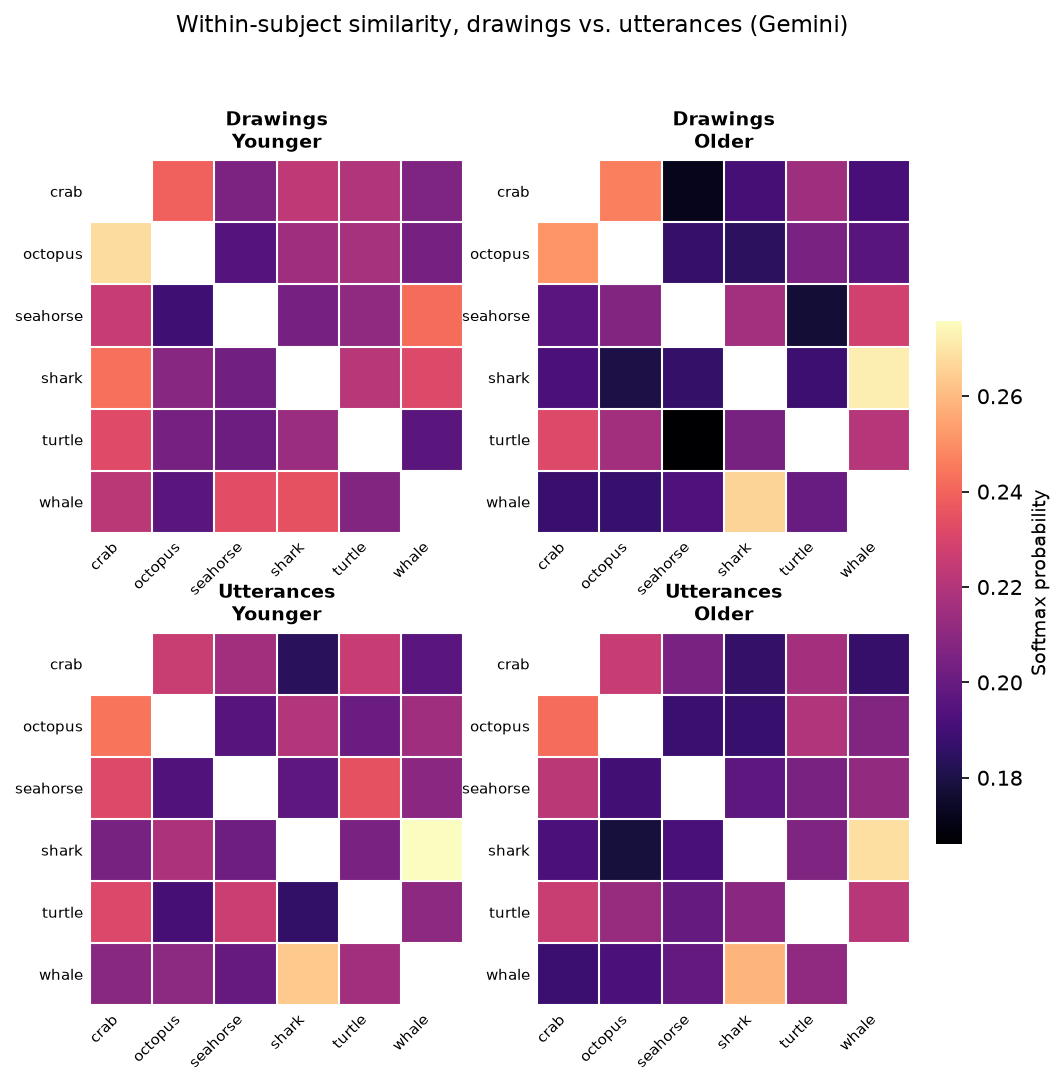

In [15]:
CM_OUT_PNG = "../figures/gemini_combined_rdm_toself.png"

row_mats = [cm_draw_younger_rdm, cm_draw_older_rdm, utt_younger_rdm, utt_older_rdm]
row_titles = ["Drawings\nYounger", "Drawings\nOlder", "Utterances\nYounger", "Utterances\nOlder"]
vmin_cm = np.nanmin(row_mats)
vmax_cm = np.nanmax(row_mats)

fig, axes = plt.subplots(2, 2, figsize=(7.5, 7.5), dpi=150)
cmap = plt.get_cmap("magma").copy()
cmap.set_bad("white")

for ax, mat, title in zip(axes.flat, row_mats, row_titles):
    masked = np.ma.masked_invalid(mat)
    im = ax.imshow(masked, cmap=cmap, vmin=vmin_cm, vmax=vmax_cm, aspect="equal")
    ax.set_xticks(range(len(CATEGORIES)))
    ax.set_xticklabels(CATEGORIES, rotation=45, ha="right", fontsize=7)
    ax.set_yticks(range(len(CATEGORIES)))
    ax.set_yticklabels(CATEGORIES, fontsize=7)
    ax.set_title(title, fontsize=9, fontweight="bold")
    ax.set_xticks(np.arange(-0.5, len(CATEGORIES), 1), minor=True)
    ax.set_yticks(np.arange(-0.5, len(CATEGORIES), 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=1.0)
    ax.tick_params(which="minor", length=0)
    ax.tick_params(which="major", length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)

cbar = fig.colorbar(im, ax=axes, fraction=0.03, pad=0.03)
cbar.set_label("Softmax probability", size=9)
cbar.outline.set_visible(False)

fig.suptitle("Within-subject similarity, drawings vs. utterances (Gemini)", fontsize=11, y=1.0)
fig.savefig(CM_OUT_PNG, dpi=200, bbox_inches="tight")
print(f"saved -> {CM_OUT_PNG}")
plt.show()

## Cross-modal scatter (plotting category pair similarity across categories)

Each point is one category pair (one lower-triangle cell): x = drawing-pair
similarity, y = utterance-pair similarity. This is the data the Spearman rho above
is computed from.

saved -> ../figures/gemini_cross_modal_rdm_scatter.png


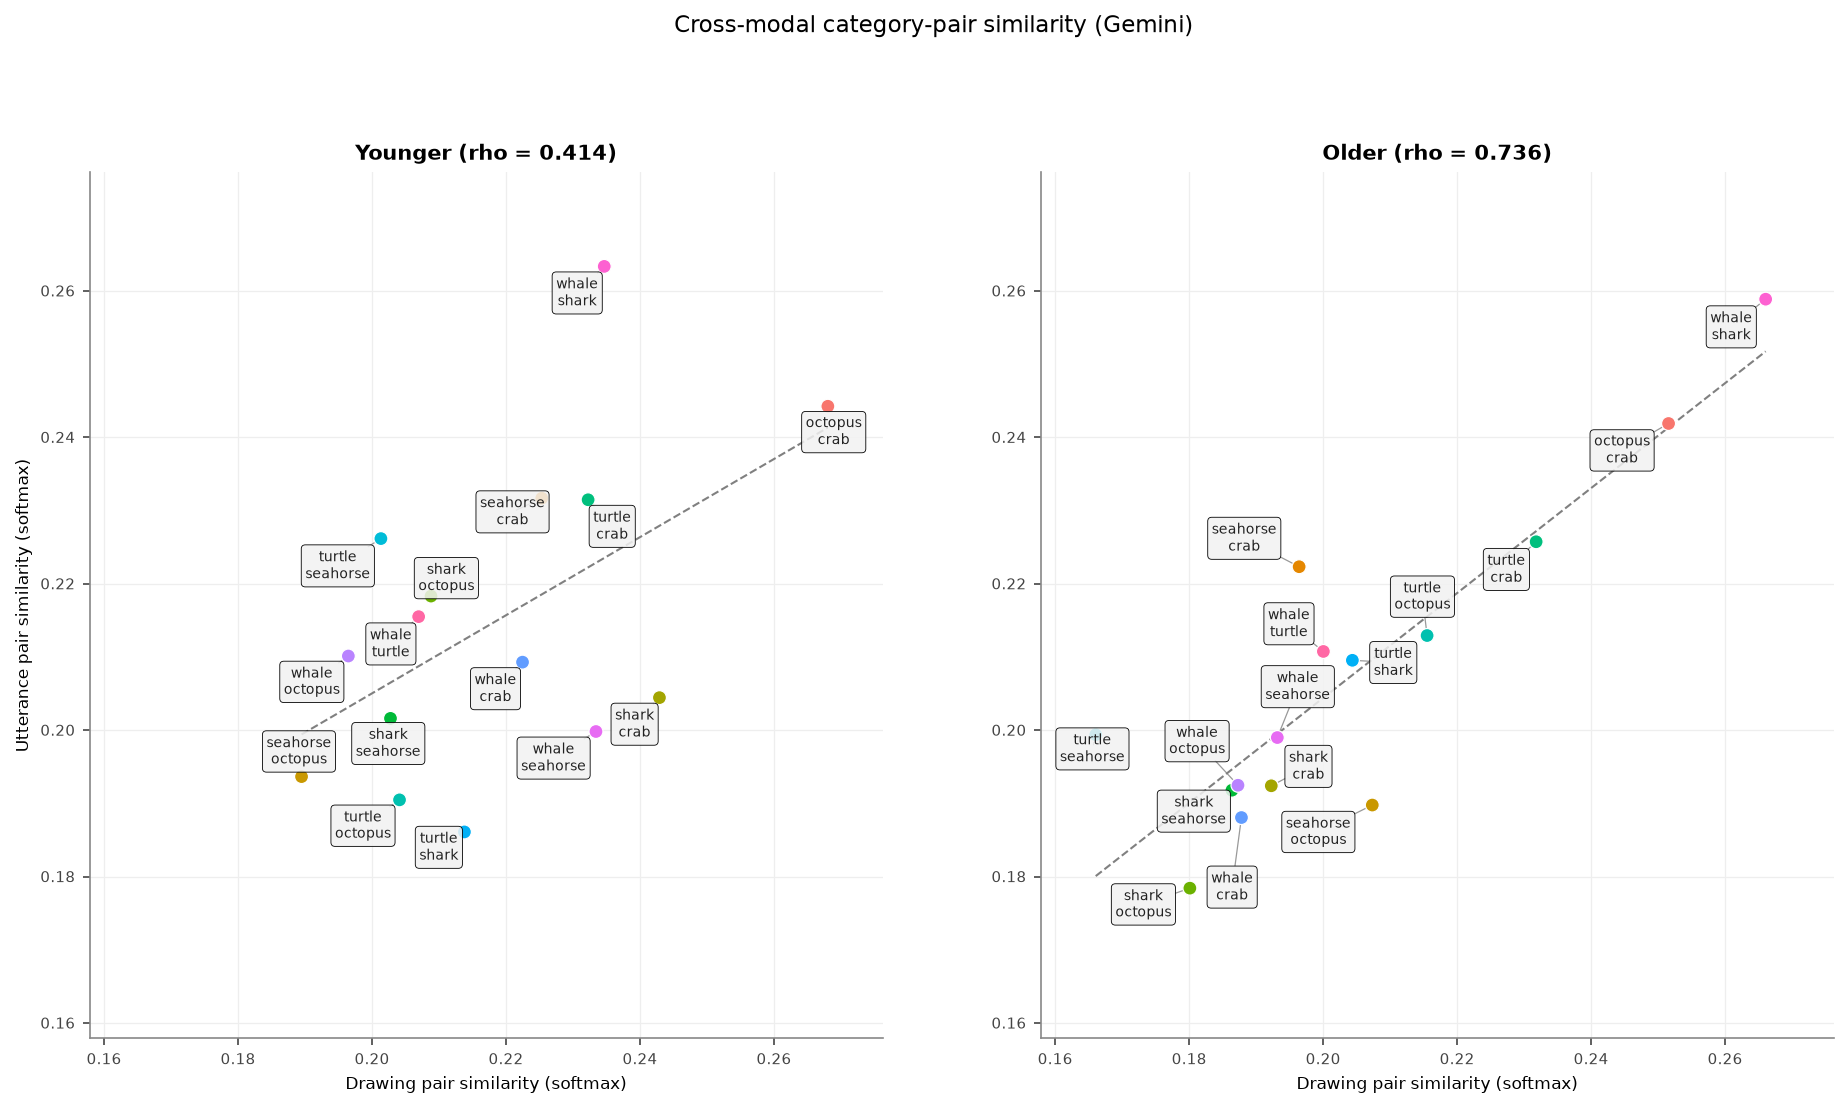

In [16]:
from adjustText import adjust_text

# Exact colors from the original: scales::hue_pal()(15) over the 15 category-pair
# labels, alphabetically sorted the way ggplot's default discrete color scale would
# (verified by running the R snippet directly rather than approximating HCL by eye).
PAIR_COLORS = {
    "octopus-crab": "#F8766D",
    "seahorse-crab": "#E58700",
    "seahorse-octopus": "#C99800",
    "shark-crab": "#A3A500",
    "shark-octopus": "#6BB100",
    "shark-seahorse": "#00BA38",
    "turtle-crab": "#00BF7D",
    "turtle-octopus": "#00C0AF",
    "turtle-seahorse": "#00BCD8",
    "turtle-shark": "#00B0F6",
    "whale-crab": "#619CFF",
    "whale-octopus": "#B983FF",
    "whale-seahorse": "#E76BF3",
    "whale-shark": "#FD61D1",
    "whale-turtle": "#FF67A4",
}


def lower_tri_pairs(draw_mat, utt_mat, categories):
    idx = np.tril_indices(len(categories), k=-1)
    rows = [categories[i] for i in idx[0]]
    cols = [categories[j] for j in idx[1]]
    return pd.DataFrame({
        "row_cat": rows, "col_cat": cols,
        "pair": [f"{r}-{c}" for r, c in zip(rows, cols)],
        "draw_prob": draw_mat[idx], "utt_prob": utt_mat[idx],
    })


younger_pairs = lower_tri_pairs(cm_draw_younger_rdm, utt_younger_rdm, CATEGORIES)
older_pairs = lower_tri_pairs(cm_draw_older_rdm, utt_older_rdm, CATEGORIES)

CM_SCATTER_PNG = "../figures/gemini_cross_modal_rdm_scatter.png"

axis_min = min(younger_pairs[["draw_prob", "utt_prob"]].min().min(), older_pairs[["draw_prob", "utt_prob"]].min().min())
axis_max = max(younger_pairs[["draw_prob", "utt_prob"]].max().max(), older_pairs[["draw_prob", "utt_prob"]].max().max())
pad = (axis_max - axis_min) * 0.08
axis_min, axis_max = axis_min - pad, axis_max + pad

fig, axes = plt.subplots(1, 2, figsize=(15, 7.5), dpi=150)

for ax, pairs, title, rho in zip(axes, [younger_pairs, older_pairs], ["Younger", "Older"], [younger_rho, older_rho]):
    xs, ys = pairs["draw_prob"].to_numpy(), pairs["utt_prob"].to_numpy()
    colors = [PAIR_COLORS[p] for p in pairs["pair"]]
    ax.scatter(xs, ys, s=45, c=colors, zorder=3, edgecolors="white", linewidths=0.6)

    b_ = np.polyfit(xs, ys, 1)  # per-panel OLS trend, dashed (no CI, matching se=FALSE in the original)
    xg = np.array([xs.min(), xs.max()])
    ax.plot(xg, np.polyval(b_, xg), color="gray", linewidth=1.0, linestyle="--", zorder=2)

    # Label boxes: grey95 fill @ 85% opacity, thin black border — matches
    # geom_label_repel(fill = alpha("grey95", 0.85), label.size = 0.2) in the original.
    texts = [
        ax.annotate(p.replace("-", "\n"), (x, y), fontsize=6.5, color="#222222",
                    ha="center", va="center", zorder=4,
                    bbox=dict(boxstyle="round,pad=0.3", fc=(0.949, 0.949, 0.949, 0.85),
                              ec="black", lw=0.4))
        for x, y, p in zip(xs, ys, pairs["pair"])
    ]
    # segment.color = "grey60", segment.size = 0.3 in the original -> thin grey leader lines.
    # Pushed harder than adjustText's defaults (force_text/force_static, more iterations,
    # bigger expand) since 15 labels in a tight cluster need real room to separate.
    adjust_text(texts, x=xs, y=ys, ax=ax,
                arrowprops=dict(arrowstyle="-", color="#999999", lw=0.6),
                expand=(1.8, 2.2),
                force_text=(0.4, 0.6),
                force_static=(0.4, 0.6),
                force_pull=(0.01, 0.01),
                iter_lim=500)

    ax.set_xlim(axis_min, axis_max)
    ax.set_ylim(axis_min, axis_max)
    ax.set_title(f"{title} (rho = {rho:.3f})", fontsize=10, fontweight="bold")
    ax.set_xlabel("Drawing pair similarity (softmax)", fontsize=8)
    if ax is axes[0]:
        ax.set_ylabel("Utterance pair similarity (softmax)", fontsize=8)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
    for spine in ("left", "bottom"):
        ax.spines[spine].set_color("#888888")
        ax.spines[spine].set_linewidth(0.8)
    ax.tick_params(colors="#444444", labelsize=7)
    ax.grid(True, color="#eeeeee", linewidth=0.6, zorder=0)
    ax.set_axisbelow(True)

fig.suptitle("Cross-modal category-pair similarity (Gemini)", fontsize=11, y=1.02)
fig.savefig(CM_SCATTER_PNG, dpi=200, bbox_inches="tight")
print(f"saved -> {CM_SCATTER_PNG}")
plt.show()